# NCAA postseason classification

Coursework: a classification exercise from IBM's *Machine Learning with Python* course (ML0101EN, via edX). The exercise prompts and the dataset come from the course; the model code and results are mine.

The notebook loads a college basketball dataset with pandas, prepares features, and compares KNN, a decision tree, an SVM and logistic regression on a small validation split.

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import pandas as pd
import numpy as np
import matplotlib.ticker as ticker
from sklearn import preprocessing
%matplotlib inline

### About dataset


`cbb.csv` has five seasons of performance data for Division I college basketball teams: games played (`G`), wins (`W`), adjusted offensive and defensive efficiency (`ADJOE`, `ADJDE`), power rating (`BARTHAG`), shooting, turnover, rebound and free-throw rates, tempo (`ADJ_T`), wins above bubble (`WAB`), and how far the team went in the postseason (`POSTSEASON`).

### Load Data From CSV File  


Load the dataset:

In [2]:
df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%206/cbb.csv')
df.head()

,TEAM,CONF,G,W,ADJOE,ADJDE,BARTHAG,EFG_O,EFG_D,TOR,...,FTRD,2P_O,2P_D,3P_O,3P_D,ADJ_T,WAB,POSTSEASON,SEED,YEAR
0,North Carolina,ACC,40,33,123.3,94.9,0.9531,52.6,48.1,15.4,...,30.4,53.9,44.6,32.7,36.2,71.7,8.6,2ND,1.0,2016
1,Villanova,BE,40,35,123.1,90.9,0.9703,56.1,46.7,16.3,...,30.0,57.4,44.1,36.2,33.9,66.7,8.9,Champions,2.0,2016
2,Notre Dame,ACC,36,24,118.3,103.3,0.8269,54.0,49.5,15.3,...,26.0,52.9,46.5,37.4,36.9,65.5,2.3,E8,6.0,2016
3,Virginia,ACC,37,29,119.9,91.0,0.9600,54.8,48.4,15.1,...,33.4,52.6,46.3,40.3,34.7,61.9,8.6,E8,1.0,2016
4,Kansas,B12,37,32,120.9,90.4,0.9662,55.7,45.1,17.8,...,37.3,52.7,43.4,41.3,32.5,70.1,11.6,E8,1.0,2016


In [3]:
df.shape

(1406, 24)

## Add Column
Next we'll add a column that will contain "true" if the wins above bubble are over 7 and "false" if not. We'll call this column Win Index or "windex" for short. 


In [4]:
df['windex'] = np.where(df.WAB > 7, 'True', 'False')

# Data visualization and pre-processing



Next we'll filter the data set to the teams that made the Sweet Sixteen, the Elite Eight, and the Final Four in the post season. We'll also create a new dataframe that will hold the values with the new column.


In [5]:
df1 = df.loc[df['POSTSEASON'].str.contains('F4|S16|E8', na=False)].copy()
df1.head()

,TEAM,CONF,G,W,ADJOE,ADJDE,BARTHAG,EFG_O,EFG_D,TOR,...,2P_O,2P_D,3P_O,3P_D,ADJ_T,WAB,POSTSEASON,SEED,YEAR,windex
2,Notre Dame,ACC,36,24,118.3,103.3,0.8269,54.0,49.5,15.3,...,52.9,46.5,37.4,36.9,65.5,2.3,E8,6.0,2016,False
3,Virginia,ACC,37,29,119.9,91.0,0.9600,54.8,48.4,15.1,...,52.6,46.3,40.3,34.7,61.9,8.6,E8,1.0,2016,True
4,Kansas,B12,37,32,120.9,90.4,0.9662,55.7,45.1,17.8,...,52.7,43.4,41.3,32.5,70.1,11.6,E8,1.0,2016,True
5,Oregon,P12,37,30,118.4,96.2,0.9163,52.3,48.9,16.1,...,52.6,46.1,34.4,36.2,69.0,6.7,E8,1.0,2016,False
6,Syracuse,ACC,37,23,111.9,93.6,0.8857,50.0,47.3,18.1,...,47.2,48.1,36.0,30.7,65.5,-0.3,F4,10.0,2016,False


In [6]:
df1['POSTSEASON'].value_counts()

POSTSEASON
S16    32
E8     16
F4      8
Name: count, dtype: int64

32 teams made it into the Sweet Sixteen, 16 into the Elite Eight, and 8 made it into the Final Four over 5 seasons. 


Let's plot some columns to understand the data better:


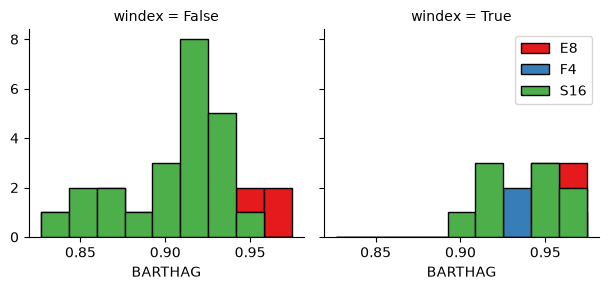

In [7]:
import seaborn as sns

bins = np.linspace(df1.BARTHAG.min(), df1.BARTHAG.max(), 10)
g = sns.FacetGrid(df1, col="windex", hue="POSTSEASON", palette="Set1", col_wrap=6)
g.map(plt.hist, 'BARTHAG', bins=bins, ec="k")

g.axes[-1].legend()
plt.show()

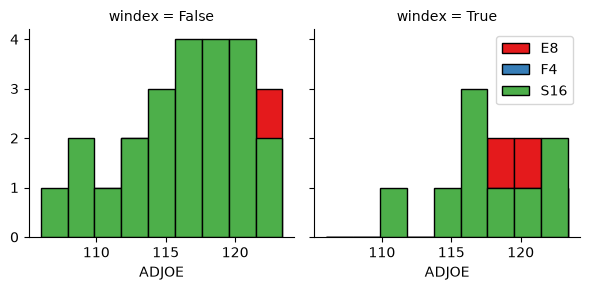

In [8]:
bins = np.linspace(df1.ADJOE.min(), df1.ADJOE.max(), 10)
g = sns.FacetGrid(df1, col="windex", hue="POSTSEASON", palette="Set1", col_wrap=2)
g.map(plt.hist, 'ADJOE', bins=bins, ec="k")

g.axes[-1].legend()
plt.show()

# Pre-processing:  Feature selection/extraction


### Let's look at how Adjusted Defense Efficiency plots


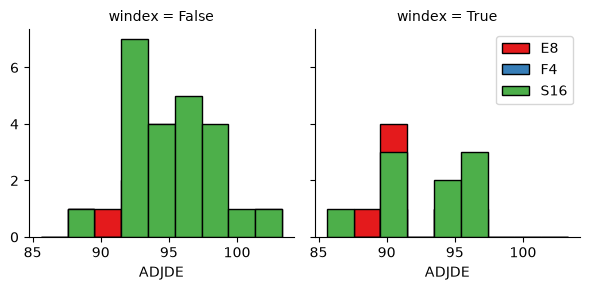

In [9]:
bins = np.linspace(df1.ADJDE.min(), df1.ADJDE.max(), 10)
g = sns.FacetGrid(df1, col="windex", hue="POSTSEASON", palette="Set1", col_wrap=2)
g.map(plt.hist, 'ADJDE', bins=bins, ec="k")
g.axes[-1].legend()
plt.show()


We see that this data point doesn't impact the ability of a team to get into the Final Four. 


## Convert Categorical features to numerical values


Let's look at the postseason:


In [10]:
df1.groupby(['windex'])['POSTSEASON'].value_counts(normalize=True)

windex  POSTSEASON
False   S16           0.605263
        E8            0.263158
        F4            0.131579
True    S16           0.500000
        E8            0.333333
        F4            0.166667
Name: proportion, dtype: float64

13% of teams with 6 or less wins above bubble make it into the final four while 17% of teams with 7 or more do.


Let's convert wins above bubble (winindex) under 7 to 0 and over 7 to 1:


In [11]:
df1['windex'] = df1['windex'].map({'False': 0, 'True': 1})
df1.head()

,TEAM,CONF,G,W,ADJOE,ADJDE,BARTHAG,EFG_O,EFG_D,TOR,...,2P_O,2P_D,3P_O,3P_D,ADJ_T,WAB,POSTSEASON,SEED,YEAR,windex
2,Notre Dame,ACC,36,24,118.3,103.3,0.8269,54.0,49.5,15.3,...,52.9,46.5,37.4,36.9,65.5,2.3,E8,6.0,2016,0
3,Virginia,ACC,37,29,119.9,91.0,0.9600,54.8,48.4,15.1,...,52.6,46.3,40.3,34.7,61.9,8.6,E8,1.0,2016,1
4,Kansas,B12,37,32,120.9,90.4,0.9662,55.7,45.1,17.8,...,52.7,43.4,41.3,32.5,70.1,11.6,E8,1.0,2016,1
5,Oregon,P12,37,30,118.4,96.2,0.9163,52.3,48.9,16.1,...,52.6,46.1,34.4,36.2,69.0,6.7,E8,1.0,2016,0
6,Syracuse,ACC,37,23,111.9,93.6,0.8857,50.0,47.3,18.1,...,47.2,48.1,36.0,30.7,65.5,-0.3,F4,10.0,2016,0


### Feature selection


Let's define feature sets, X:


In [12]:
X = df1[['G', 'W', 'ADJOE', 'ADJDE', 'BARTHAG', 'EFG_O', 'EFG_D',
       'TOR', 'TORD', 'ORB', 'DRB', 'FTR', 'FTRD', '2P_O', '2P_D', '3P_O',
       '3P_D', 'ADJ_T', 'WAB', 'SEED', 'windex']]
X[0:5]

,G,W,ADJOE,ADJDE,BARTHAG,EFG_O,EFG_D,TOR,TORD,ORB,...,FTR,FTRD,2P_O,2P_D,3P_O,3P_D,ADJ_T,WAB,SEED,windex
2,36,24,118.3,103.3,0.8269,54.0,49.5,15.3,14.8,32.7,...,32.9,26.0,52.9,46.5,37.4,36.9,65.5,2.3,6.0,0
3,37,29,119.9,91.0,0.9600,54.8,48.4,15.1,18.8,29.9,...,32.1,33.4,52.6,46.3,40.3,34.7,61.9,8.6,1.0,1
4,37,32,120.9,90.4,0.9662,55.7,45.1,17.8,18.5,32.2,...,38.6,37.3,52.7,43.4,41.3,32.5,70.1,11.6,1.0,1
5,37,30,118.4,96.2,0.9163,52.3,48.9,16.1,20.2,34.1,...,40.3,32.0,52.6,46.1,34.4,36.2,69.0,6.7,1.0,0
6,37,23,111.9,93.6,0.8857,50.0,47.3,18.1,20.4,33.5,...,35.4,28.0,47.2,48.1,36.0,30.7,65.5,-0.3,10.0,0


What are our labels? Round where the given team was eliminated or where their season ended (R68 = First Four, R64 = Round of 64, R32 = Round of 32, S16 = Sweet Sixteen, E8 = Elite Eight, F4 = Final Four, 2ND = Runner-up, Champion = Winner of the NCAA March Madness Tournament for that given year)|


In [13]:
y = df1['POSTSEASON'].values
y[0:5]

<StringArray>
['E8', 'E8', 'E8', 'E8', 'F4']
Length: 5, dtype: str

## Normalize Data 


Data Standardization gives data zero mean and unit variance (technically should be done after train test split )


In [14]:
X= preprocessing.StandardScaler().fit(X).transform(X)
X[0:5]

array([[-0.43331874, -1.26140173,  0.28034482,  2.74329908, -2.45717765,
         0.10027963,  0.94171924, -1.16188145, -1.71391372,  0.12750511,
         1.33368704, -0.4942211 , -0.87998988,  0.02784185,  0.00307239,
         0.22576157,  1.59744386, -1.12106011, -1.0448016 ,  0.49716104,
        -0.6882472 ],
       [ 0.40343468,  0.35874728,  0.64758014, -0.90102957,  1.127076  ,
         0.39390887,  0.38123706, -1.29466791, -0.03522254, -0.62979797,
        -1.31585883, -0.68542235,  0.55458056, -0.07167795, -0.0829545 ,
         1.32677295,  0.65081046, -2.369021  ,  0.98050611, -1.14054592,
         1.45296631],
       [ 0.40343468,  1.33083669,  0.87710222, -1.0788017 ,  1.29403598,
         0.72424177, -1.30020946,  0.49794919, -0.16112438, -0.00772758,
        -0.27908001,  0.86808783,  1.31063795, -0.03850468, -1.33034432,
         1.70643205, -0.29582294,  0.47355659,  1.94493836, -1.14054592,
         1.45296631],
       [ 0.40343468,  0.68277708,  0.30329703,  0.63966222

## Training and Validation 


Split the data into Training and Validation data.


In [15]:
# We split the X into train and test to find the best k
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=4)
print ('Train set:', X_train.shape,  y_train.shape)
print ('Validation set:', X_val.shape,  y_val.shape)

Train set: (44, 21) (44,)
Validation set: (12, 21) (12,)


# Classification 


Now, it is your turn, use the training set to build an accurate model. Then use the validation set  to report the accuracy of the model
You should use the following algorithm:
- K Nearest Neighbor(KNN)
- Decision Tree
- Support Vector Machine
- Logistic Regression



# K Nearest Neighbor(KNN)

<b>Question 1 </b> Build a KNN model using a value of k equals five, find the accuracy on the validation data (X_val and y_val)


You can use <code> accuracy_score</code>


In [16]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_val)
accuracy_knn = accuracy_score(y_val, y_pred_knn)
print(f'Accuracy on validation data: {accuracy_knn:.4f}')

Accuracy on validation data: 0.6667


<b>Question 2</b> Determine and print the accuracy for the first 15 values of k on the validation data:


In [17]:
for k in range(1, 16):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    accuracy_knn = accuracy_score(y_val, y_pred_knn)
    print(f'Accuracy for k={k}: {accuracy_knn:.4f}')

Accuracy for k=1: 0.6667
Accuracy for k=2: 0.6667
Accuracy for k=3: 0.6667
Accuracy for k=4: 0.6667
Accuracy for k=5: 0.6667
Accuracy for k=6: 0.6667
Accuracy for k=7: 0.6667
Accuracy for k=8: 0.6667
Accuracy for k=9: 0.6667
Accuracy for k=10: 0.6667
Accuracy for k=11: 0.6667
Accuracy for k=12: 0.6667
Accuracy for k=13: 0.6667
Accuracy for k=14: 0.6667
Accuracy for k=15: 0.6667


# Decision Tree


The following lines of code fit a <code>DecisionTreeClassifier</code>:


In [18]:
from sklearn.tree import DecisionTreeClassifier

<b>Question 3</b> Determine the minimum value for the parameter <code>max_depth</code> that improves results 


In [19]:
baseline_model = DecisionTreeClassifier()
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_val)
baseline_accuracy = accuracy_score(y_val, baseline_pred)

print(f'Baseline accuracy (without max_depth): {baseline_accuracy:.4f}')
improving_accuracy = baseline_accuracy
min_improving_depth = None

for depth in range(1, 21):  # Adjust range if necessary
    model = DecisionTreeClassifier(max_depth=depth)
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    accuracy = accuracy_score(y_val, val_pred)
    
    print(f'Accuracy for max_depth={depth}: {accuracy:.4f}')
    
    if accuracy > improving_accuracy:
        improving_accuracy = accuracy
        min_improving_depth = depth
        break  # Exit the loop once we find an improvement

if min_improving_depth is not None:
    print(f'Minimum max_depth that improves results: {min_improving_depth} with accuracy {improving_accuracy:.4f}')
else:
    print('No improvement found within the tested range of max_depth values')


Baseline accuracy (without max_depth): 0.4167
Accuracy for max_depth=1: 0.6667
Minimum max_depth that improves results: 1 with accuracy 0.6667


# Support Vector Machine


<b>Question 4</b> Train the support vector machine model and determine the accuracy on the validation data for each kernel. Find the kernel (linear, poly, rbf, sigmoid) that provides the best score on the validation data and train a SVM using it.


In [20]:
from sklearn import svm
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [21]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
best_kernel = None
best_accuracy = 0.0
for kernel in kernels:
    svm = SVC(kernel=kernel)
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_val)
    accuracy = accuracy_score(y_val, y_pred)
    
    print(f'Accuracy with {kernel} kernel: {accuracy:.4f}')
    
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_kernel = kernel
print(f'\nBest kernel: {best_kernel} with accuracy: {best_accuracy:.4f}')
best_svm = SVC(kernel=best_kernel)
best_svm.fit(X_train, y_train)
y_best_pred = best_svm.predict(X_val)
best_accuracy_confirm = accuracy_score(y_val, y_best_pred)
print(f'Confirmed accuracy with best kernel ({best_kernel}): {best_accuracy_confirm:.4f}')

Accuracy with linear kernel: 0.2500
Accuracy with poly kernel: 0.6667
Accuracy with rbf kernel: 0.5833
Accuracy with sigmoid kernel: 0.5833

Best kernel: poly with accuracy: 0.6667
Confirmed accuracy with best kernel (poly): 0.6667


# Logistic Regression


<b>Question 5</b> Train a logistic regression model and determine the accuracy of the validation data (set C=0.01)


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [23]:
log_reg = LogisticRegression(C=0.01, max_iter=1000)
log_reg.fit(X_train, y_train)
y_val_pred_lr = log_reg.predict(X_val)
accuracy_lr = accuracy_score(y_val, y_val_pred_lr)
print(f'Accuracy on validation data with Logistic Regression (C=0.01): {accuracy_lr:.4f}')

Accuracy on validation data with Logistic Regression (C=0.01): 0.5833


# Model Evaluation using Test set


In [24]:
from sklearn.metrics import f1_score
# for f1_score please set the average parameter to 'micro'
from sklearn.metrics import log_loss

In [25]:
def jaccard_index(predictions, true):
    if (len(predictions) == len(true)):
        intersect = 0;
        for x,y in zip(predictions, true):
            if (x == y):
                intersect += 1
        return intersect / (len(predictions) + len(true) - intersect)
    else:
        return -1

<b>Question 5</b> Calculate the  F1 score and Jaccard score for each model from above. Use the Hyperparameter that performed best on the validation data. **For f1_score please set the average parameter to 'micro'.**


### Load Test set for evaluation 


In [26]:
test_df = pd.read_csv('https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/ML0120ENv3/Dataset/ML0101EN_EDX_skill_up/basketball_train.csv', on_bad_lines='skip')
test_df.head()

,TEAM,CONF,G,W,ADJOE,ADJDE,BARTHAG,EFG_O,EFG_D,TOR,...,FTRD,2P_O,2P_D,3P_O,3P_D,ADJ_T,WAB,POSTSEASON,SEED,YEAR
0,North Carolina,ACC,40,33,123.3,94.9,0.9531,52.6,48.1,15.4,...,30.4,53.9,44.6,32.7,36.2,71.7,8.6,2ND,1.0,2016
1,Villanova,BE,40,35,123.1,90.9,0.9703,56.1,46.7,16.3,...,30.0,57.4,44.1,36.2,33.9,66.7,8.9,Champions,2.0,2016
2,Notre Dame,ACC,36,24,118.3,103.3,0.8269,54.0,49.5,15.3,...,26.0,52.9,46.5,37.4,36.9,65.5,2.3,E8,6.0,2016
3,Virginia,ACC,37,29,119.9,91.0,0.9600,54.8,48.4,15.1,...,33.4,52.6,46.3,40.3,34.7,61.9,8.6,E8,1.0,2016
4,Kansas,B12,37,32,120.9,90.4,0.9662,55.7,45.1,17.8,...,37.3,52.7,43.4,41.3,32.5,70.1,11.6,E8,1.0,2016


In [27]:
test_df['windex'] = np.where(test_df.WAB > 7, 'True', 'False')
test_df1 = test_df[test_df['POSTSEASON'].str.contains('F4|S16|E8', na=False)]
test_Feature = test_df1[['G', 'W', 'ADJOE', 'ADJDE', 'BARTHAG', 'EFG_O', 'EFG_D',
       'TOR', 'TORD', 'ORB', 'DRB', 'FTR', 'FTRD', '2P_O', '2P_D', '3P_O',
       '3P_D', 'ADJ_T', 'WAB', 'SEED', 'windex']]
test_Feature = test_Feature.copy()
test_Feature['windex'] = test_Feature['windex'].map({'False': 0, 'True': 1})
test_X=test_Feature
test_X= preprocessing.StandardScaler().fit(test_X).transform(test_X)
test_X[0:5]

array([[-4.08074446e-01, -1.10135297e+00,  3.37365934e-01,
         2.66479976e+00, -2.46831661e+00,  2.13703245e-01,
         9.44090550e-01, -1.19216365e+00, -1.64348924e+00,
         1.45405982e-02,  1.29523097e+00, -6.23533182e-01,
        -9.31788560e-01,  1.42784371e-01,  1.68876201e-01,
         2.84500844e-01,  1.62625961e+00, -8.36649260e-01,
        -9.98500539e-01,  4.84319174e-01, -6.77003200e-01],
       [ 3.63958290e-01,  3.26326807e-01,  7.03145068e-01,
        -7.13778644e-01,  1.07370841e+00,  4.82633172e-01,
         4.77498943e-01, -1.32975879e+00, -6.86193316e-02,
        -7.35448152e-01, -1.35447914e+00, -8.06829025e-01,
         3.41737757e-01,  4.96641291e-02,  9.40576311e-02,
         1.37214061e+00,  6.93854620e-01, -2.00860931e+00,
         9.80549967e-01, -1.19401460e+00,  1.47709789e+00],
       [ 3.63958290e-01,  1.18293467e+00,  9.31757027e-01,
        -8.78587347e-01,  1.23870131e+00,  7.85179340e-01,
        -9.22275877e-01,  5.27775662e-01, -1.86734575e

In [28]:
test_y = test_df1['POSTSEASON'].values
test_y[0:5]

<StringArray>
['E8', 'E8', 'E8', 'E8', 'F4']
Length: 5, dtype: str

KNN


In [29]:
knn_f1 = f1_score(y_val, y_pred_knn, average='micro')
knn_jaccard_custom = jaccard_index(y_pred_knn, y_val)
print(f'KNN (k=5) - F1 Score: {knn_f1:.4f}',f'Jaccard Score: {knn_jaccard_custom:.4f}')

KNN (k=5) - F1 Score: 0.6667 Jaccard Score: 0.5000


Decision Tree


In [30]:
dt_f1 = f1_score(y_val, baseline_pred, average='micro')
dt_jaccard_custom = jaccard_index(baseline_pred, y_val)
print(f'F1 Score: {dt_f1:.4f}',f'Jaccard Score: {dt_jaccard_custom:.4f}')

F1 Score: 0.4167 Jaccard Score: 0.2632


SVM


In [31]:
svm_f1 = f1_score(y_val, y_best_pred, average='micro')
svm_jaccard_custom = jaccard_index(y_best_pred, y_val)
print(f'F1 Score: {svm_f1:.4f}',f'Jaccard Score: {svm_jaccard_custom:.4f}')

F1 Score: 0.6667 Jaccard Score: 0.5000


Logistic Regression


In [32]:
lr_f1 = f1_score(y_val, y_val_pred_lr, average='micro')
lr_jaccard_custom = jaccard_index(y_val_pred_lr, y_val)
print(f'F1 Score: {lr_f1:.4f}',f'Jaccard Score: {lr_jaccard_custom:.4f}')

F1 Score: 0.5833 Jaccard Score: 0.4118


Something to keep in mind when creating models to predict the results of basketball tournaments or sports in general is that is quite hard due to so many factors influencing the game. Even in sports betting an accuracy of 55% and over is considered good as it indicates profits.
